In [1]:
# ── 0. 환경 설정 ──────────────────────────────────────────
# 1) 필요한 모듈 import: os, re, time, uuid, pickle, pathlib.Path
# 2) python-dotenv 의 load_dotenv import
import os # 운영체제 기능(환경변수, 파일, 폴더 다루기위한 기능)
import re # 정규표현식으로 문자열 패턴, 만든 검사, 치환, 추출 등 다양한 문자열 처리 기능
import time # 시간 관련 기능 시간 측정, (체인 답변 생성 시간 측정)
import uuid # 고유한 id 생성 (체인 답변 생성 시 id 부여) 요약본, 원본을 doc_id로 페어링
import pickle # 파이썬 객체를 직렬화/역직렬화(저장/복원)하는 기능
import sys  # (추가) src 폴더 import 용
from pathlib import Path # 운영체제에 상관없이 경로를 다루기 위한 기능 (폴더, 파일 경로 생성, 확인, 탐색 등)
from dotenv import load_dotenv # 환경변수(.env) 파일을 로드하는 기능
# 3) .env 가 있는 폴더를 프로젝트 루트로 자동 탐색
#    - Path.cwd() 와 그 상위 폴더(parents)를 차례로 확인해 (p / ".env") 가 존재하는 첫 경로를 PROJECT_ROOT 로 지정
#    - 찾지 못하면 Path.cwd() 를 사용
#    - PROJECT_ROOT 출력 → c:\workspaces\multimodal-rag 이면 정상
PROJECT_ROOT = next((p for p in [Path.cwd(),*Path.cwd().parents] if (p / ".env").exists()), Path.cwd())
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
# 4) PROJECT_ROOT 의 .env 파일 로드 (load_dotenv)
load_dotenv(PROJECT_ROOT / ".env")
# 5) OPENAI_API_KEY 가 없으면 ValueError 발생시키기
try:
    openai_api_key = os.environ["OPENAI_API_KEY"]
    if not openai_api_key.strip():
        raise ValueError("OPENAI_API_KEY 값이 비어있음")
except KeyError:
    raise ValueError("OPENAI_API_KEY 가 아예 존재하지 않음")

# (추가) src 폴더의 함수 불러오기
sys.path.append(str(PROJECT_ROOT))
from src.extract import extract_pdf_elements, categorize_elements
from src.summarize import generate_text_summaries, encode_image, image_summarize, generate_img_summaries
from src.retriever import id_key, add_documents, split_image_text_types, img_prompt_func

PROJECT_ROOT: c:\workspaces\multimodal-rag
extract_pdf_elements 정의 완료-> 이게 하나의 기능
categorize_elements 정의 완료-> 추출한 요소들을 테이블과 텍스트로 분류하는 기능


In [2]:
# TODO 1: 본인의 PDF 파일 이름으로 바꾸세요 (예: "invest.pdf")
# pdf_path = Path(r"C:\workspaces\multimodal-rag\invest\invest.pdf")
# pdf_dir = pdf_path.parent
# fname = pdf_path.name
fname = "[보도자료] 경제상황 평가(2026.10월)_FFF.pdf"
pdf_dir = Path("../data")          # practice 기준 → multimodal-rag\invest
pdf_path = pdf_dir / fname

fpath = str(pdf_dir) + os.sep

print("현재 위치 : " , Path.cwd())
print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 폴더     :", pdf_dir ,pdf_path.resolve())
print("PDF 존재 여부:", pdf_path.exists())

현재 위치 :  c:\workspaces\multimodal-rag\notebooks
프로젝트 루트: c:\workspaces\multimodal-rag
PDF 폴더     : ..\data C:\workspaces\multimodal-rag\data\[보도자료] 경제상황 평가(2026.10월)_FFF.pdf
PDF 존재 여부: True


In [3]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 949.81it/s]


추출 완료 — 185.4초 소요
추출된 전체 요소 수: 17


In [4]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

텍스트 블록 수: 12
표 블록 수    : 5


In [5]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 12개
Table                 : 5개


In [6]:
from pathlib import Path
figures_dir = Path(fpath) / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("✗ figures 폴더가 없습니다.")
    print("  → TODO 2, TODO 3 을 다시 확인하세요.")

추출된 이미지: 41개

  figure-1-1.jpg  (16 KB)
  figure-1-2.jpg  (26 KB)
  figure-10-20.jpg  (72 KB)
  figure-10-21.jpg  (58 KB)
  figure-10-22.jpg  (54 KB)
  figure-11-23.jpg  (36 KB)
  figure-11-24.jpg  (63 KB)
  figure-12-25.jpg  (58 KB)
  figure-12-26.jpg  (82 KB)
  figure-12-27.jpg  (40 KB)


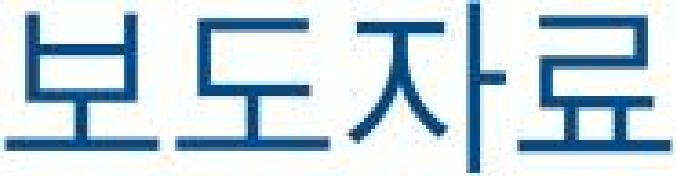

In [7]:
# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

In [8]:
from langchain_text_splitters import CharacterTextSplitter  # (추가) 01-[4] 에 있던 import

text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 12
분할 후 블록 수: 18
전체 글자 수  : 19837


In [9]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
2026년 10월 22일 공보 2026-10-17호

Hote

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조

[분할 texts_2k_token[0]] 앞 300자
2026년 10월 22일 공보 2026-10-17호

Hote

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조


In [10]:
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

저장 완료: c:\workspaces\multimodal-rag\data\processed\extracted.pkl


In [11]:
# ⌨️ 3-1. 시작 시각을 기록합니다.

# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.

start = time.time()

text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True
)

print(f"요약 완료 — {time.time() - start:.1f}초 소요")
print("텍스트 요약 수:", len(text_summaries))
print("표 요약 수    :", len(table_summaries))

요약 완료 — 30.6초 소요
텍스트 요약 수: 18
표 요약 수    : 5


In [12]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("-" *60)
print("원본임 - 앞 300자")
print(texts_2k_token[0][:300])
print()
# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("-" *60)
print("요약본임")
print(text_summaries[0])
print()
# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
origin = len(texts_2k_token[0])
summ = len(text_summaries[0])
print(f"압축률 : {origin}자 ->{summ} 자 ({summ/origin *100:.1f}%) ")

------------------------------------------------------------
원본임 - 앞 300자
2026년 10월 22일 공보 2026-10-17호

Hote

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조

------------------------------------------------------------
요약본임
**2026년 10월 경제상황 평가 요약**

- **국내경제**: 중동지역의 불확실성에도 불구하고 반도체 경기 호조와 다른 부문으로의 긍정적 파급 효과로 인해 높은 성장세가 예상됨.
- **물가상승률**: 누적된 비용 압력과 확대되는 수요 압력으로 인해 높은 수준이 지속될 것으로 보임.
- **불확실성 요인**: 반도체 경기와 중동 상황 등 여러 불확실성이 전망에 영향을 미칠 가능성이 있음.

**세계경제**:
- 높은 에너지 가격에도 불구하고 AI 투자 덕분에 양호한 성장세 지속 예상.
- 세계교역은 지정학적 리스크와 통상 갈등으로 제약받지만, AI 인프라 투자 관련 교역은 증가할 전망.
- 국제유가는 중동 상황에 따라 변동하겠으나, 중장기적으로는 공급 증가로 하락할 것으로 예상됨.
- 글로벌 반도체 경기는 AI 관련 투자 덕분에 견조하나, 수익화 및 투자 속도에 대한 불확실성이 존재함.

압축률 : 1195자 ->448 자 (37.5%) 


In [13]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.

# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
if table_summaries:
    print(f"표 요약 => {len(table_summaries)} 건 생성됨 \n")
    print("[표 요약 예시]")
    print(table_summaries[0])

    for i , summary in enumerate(table_summaries[:3]):
        print("="*60)
        print(f"[표 요약 {i+1}]")
        print("="*60)
        print(summary)
        print()

#원본 표와 함께 비교하고 싶다. zip(tables, table_summaries) 두리스트에서 같은 순번끼리 하나씩 꺼낸다.
#하나씩 꺼낸다.  요약은 원본 순서대로 만들어 졌으므로 [0] [0]끼리, [1] [1] 짝을 맞춰서
    for i, (table,summary) in  enumerate(zip(tables[:2], table_summaries[:2])):
        print("="*60)
        print(f"[표 {i+1} 원본 (앞 300자)]")
        print("="*60)
        print(table[:300])
        print()
        print("="*60)
        print(f"[표 {i+1} 요약]")
        print("="*60)
        print(summary)
        print()
    else:   # ⚠️ (참고) 이 else 는 for 에 붙어 있어 항상 실행됨. 맨 위 if 와 같은 들여쓰기로 옮겨야 의도대로 동작
        print("표 요약 비어이쓰")

표 요약 => 5 건 생성됨 

[표 요약 예시]
**요약:**  
- **경제성장**: 조사총괄팀 - 이종웅 (02-759-4202), 최영우 (4167), 추성윤 (4172)  
- **세계경제**: 국제종합팀 - 김보희 (4280)  
- **경상수지**: 국제무역팀 - 남석모 (4190)  
- **물가동향**: 물가동향팀 - 원영진 (4220)  
- **고용·임금**: 고용동향팀 - 선진산 (4205)  
- **경제모형**: 모형전망팀 - 박병국 (4137)  
[표 요약 1]
**요약:**  
- **경제성장**: 조사총괄팀 - 이종웅 (02-759-4202), 최영우 (4167), 추성윤 (4172)  
- **세계경제**: 국제종합팀 - 김보희 (4280)  
- **경상수지**: 국제무역팀 - 남석모 (4190)  
- **물가동향**: 물가동향팀 - 원영진 (4220)  
- **고용·임금**: 고용동향팀 - 선진산 (4205)  
- **경제모형**: 모형전망팀 - 박병국 (4137)  

[표 요약 2]
**2024년 경제 지표 요약 (전기대비, %)**

- **GDP 성장률**: 
  - 1분기: 3.0%, 2분기: 2.3%, 3분기: 0.2%, 4분기: 2.5%
  - 연간: 1.3% (1분기: 1.2%, 2분기: 0.2%, 3분기: 0.0%, 4분기: 0.6%)

- **산업생산**: 
  - 1분기: -0.7%, 2분기: 1.1%, 3분기: -0.5%, 4분기: 0.3%
  - 연간: -3.0% (1분기: 1.8%, 2분기: 0.1%, 3분기: -1.0%)

- **소매판매**: 
  - 미소매판매: 1.5%, 3.2%, 0.6%, 0.8%
  - 유로소매판매: 1.3%, 2.5%, 0.6%, 0.3%

- **소비자물가**: 
  - 국: 2.9%, 2.6%, 2.7%, 2.7%
  - 유로: 2.4%, 2.1%, 2.1%, 2.0%

- **비농업취업자수 증감**: 
  - 1,826천명 (1분기: 764천명, 2분기: -

In [14]:
# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.

# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.
image_files = sorted( # 3.이름순으로 정렬해서 리스트로 반환하겠다.
    f for f in figures_dir.iterdir() # 1.폴더안의 항목들을 하나씩 꺼내
    if f.suffix.lower()in (".jpg",".jpeg",".png") # 2.확장자가 이미지인 것만 
)
sample_b64 =encode_image(image_files[0])
print("원본파일 =>", image_files[0].name)
print("문자열길이 :", len(sample_b64), "자")
print("앞 100자 :", sample_b64[:100])

원본파일 => figure-1-1.jpg
문자열길이 : 22220 자
앞 100자 : /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


In [15]:
# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.

print(image_summarize(sample_b64, test_prompt))

보도자료라는 텍스트가 있는 이미지.


In [16]:
# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.
start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))

print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print("요약된 이미지 수:", len(image_summaries))

이미지 요약 완료 — 179.6초 소요
요약된 이미지 수: 41


[0] figure-1-1.jpg


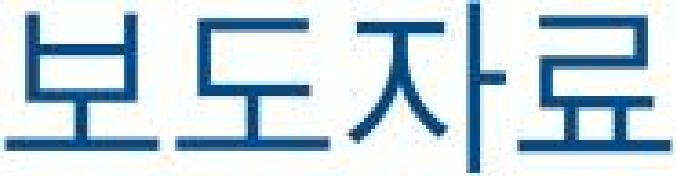

요약: 로고 이미지입니다.

[1] figure-1-2.jpg


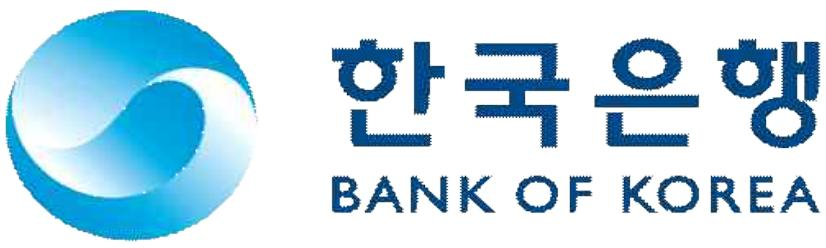

요약: 로고 이미지입니다.



In [17]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
from IPython.display import Image, display
# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.
for i, (img_file, summary) in enumerate(zip(image_files[:2], image_summaries[:2])):
    print("="*60)
    print(f"[{i}] {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file),width=450))
    print("요약:", summary)
    print()

In [18]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.

import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")

input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")

텍스트 요약 토큰 사용량 (추정)
  입력 : 13,516 토큰
  출력 : 4,256 토큰
  합계 : 17,772 토큰

요약한 이미지 수: 41 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


In [19]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)

# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list

# ⌨️ 11-3. 저장 경로를 출력합니다.

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        },
        f,
    )

print("저장 완료:", output_dir / "summaries.pkl")

저장 완료: c:\workspaces\multimodal-rag\data\processed\summaries.pkl


In [20]:
# ── 2. 검색기 만들기 ──────────────────────────────────────
# langchain 1.x 에서 두 클래스의 위치가 바뀌었습니다.
# 어느 버전을 설치했든 동작하도록 두 경로를 모두 시도합니다. (try / except ImportError)

# 1) MultiVectorRetriever import
#    - langchain 1.x : langchain_classic.retrievers.multi_vector
#    - langchain 0.3 : langchain.retrievers.multi_vector
try:
    from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
except ImportError:
    print("MultiVectorRetriever import 실패, langchain.retrievers.multi_vector 로 시도")
    from langchain.retrievers.multi_vector import MultiVectorRetriever  # (수정) 실제로 시도하도록 추가
# 2) InMemoryStore import
#    - langchain 1.x : langchain_core.stores
#    - langchain 0.3 : langchain.storage
try:
    from langchain_core.stores import InMemoryStore
except ImportError:
    print("InMemoryStore import 실패, langchain.storage 로 시도")
    from langchain.storage import InMemoryStore  # (수정) 실제로 시도하도록 추가
# 3) Chroma(langchain_chroma), OpenAIEmbeddings(langchain_openai) import
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings
# 4) 요약문이 들어갈 벡터 DB (= 색인 카드 서랍)
#    - collection_name="multimodal_rag"
#    - embedding_function = OpenAIEmbeddings(model="text-embedding-3-small")
vectorstore = Chroma(collection_name="multimodal_rag", embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"))
# 5) 원본이 들어갈 저장소 (= 서가) : InMemoryStore()
store = InMemoryStore()
# 6) 연결 키(= 청구기호) : id_key = "doc_id"  → src/retriever.py 에서 import 함
# 7) MultiVectorRetriever(vectorstore=..., docstore=..., id_key=...) 생성
retriever = MultiVectorRetriever(vectorstore=vectorstore, docstore=store, id_key=id_key)
# 8) "검색기 생성 완료" 출력
print("검색기 생성 완료")

검색기 생성 완료


In [21]:
# ── 3. 요약과 원본을 같은 ID로 짝짓기 ─────────────────────
# 3) 데이터가 있을 때만 각각 저장
#    - text_summaries  ↔ texts_2k_token
#    - table_summaries ↔ tables
#    - image_summaries ↔ img_base64_list
if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)
# 4) "색인 완료" 와 벡터 DB에 저장된 요약 수 출력 (vectorstore.get()["ids"] 의 길이)
# ⚠️ 이 셀을 두 번 실행하면 데이터가 중복됩니다.
print(f"색인 완료: vectorstore에 저장된 요약 수 = {len(vectorstore.get()['ids'])}")

색인 완료: vectorstore에 저장된 요약 수 = 64


In [22]:
# ── 4. 검색 테스트 ────────────────────────────────────────
# TODO 3: 그래프나 표를 봐야만 답할 수 있는 질문을 query 에 적으세요
query = "본인 PDF의 그래프·표를 봐야 답할 수 있는 질문"
# 1) retriever.invoke(query) 결과를 found 에 저장
found = retriever.invoke(query)
#리트리버(retriever)는 
#           1. 질문을 임베딩으로 바꾼다.
#           2. 백터스토어(vectorstore)에서 질문과 유사한 요약문을 찾는다(chroma 에서)
#           3. 찾은 요약의 metadata["doc_id"] 를 이용해 docstore에서 원본을 찾는다
#           4. doc_id(번호표)와 원본(책)을 꺼내서 found 에 저장(inmemorystore)

# 2) 검색된 원본 수 출력
print(f"검색된 원본 수: {len(found)}")
# 3) found 를 순회하며
#    - content = doc.page_content (Document 가 아니면 doc 그대로)
#    - 정규식 "^[A-Za-z0-9+/]{100,}={0,2}$" 에 맞으면 "이미지(Base64)", 아니면 "텍스트/표"
#    - 종류, 길이, 앞 120자(줄바꿈 제거) 출력
for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_image = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    #Base64에 쓰는 문자만 100개 이상이어지고, 끝에 =이 0~2개 붙은 문자열은 이미지다.
    kind = "이미지(Base64)" if is_image else "텍스트/표"
    print(f"[{i}] {kind} — 길이 {len(content):,}자")
    print("   ", content[:120].replace("\n", " "), "...")
    print()

검색된 원본 수: 4
[0] 이미지(Base64) — 길이 54,776자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[1] 이미지(Base64) — 길이 69,820자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[2] 이미지(Base64) — 길이 117,104자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[3] 이미지(Base64) — 길이 98,544자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...



In [23]:
# ── 5. 검색 결과를 텍스트와 이미지로 분리 ─────────────────
# 3) 앞서 검색한 결과(found)로 동작 확인 → 이미지 / 텍스트 건수 출력
split_data = split_image_text_types(found)
print("이미지:" , len(split_data["images"]), "건")
print("표:" , len(split_data["texts"]), "건")

이미지: 4 건
표: 0 건


In [24]:
# ── 6. 최종 멀티모달 체인 만들기 ──────────────────────────
# 1) import
#    - HumanMessage (langchain_core.messages)
#    - StrOutputParser (langchain_core.output_parsers)
#    - ChatPromptTemplate (langchain_core.prompts)
#    - RunnableLambda, RunnablePassthrough (langchain_core.runnables)
#    - ChatOpenAI (langchain_openai)
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_openai import ChatOpenAI

# 2) img_prompt_func → src/retriever.py 에서 import 함

# 3) 모델: ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)
model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)
# 4) 체인 조립 (LCEL)
#    {"context": retriever | RunnableLambda(split_image_text_types),
#     "question": RunnablePassthrough()}
#    | RunnableLambda(img_prompt_func)
#    | TODO 5: 멀티모달 LLM 변수
#    | StrOutputParser()
chain = (
    {"context": retriever | RunnableLambda(split_image_text_types),
     "question": RunnablePassthrough()}
    | RunnableLambda(img_prompt_func)
    | model
    | StrOutputParser()
)
# 5) "최종 체인 조립 완료" 출력
print("최종 체인 조립 완료")

최종 체인 조립 완료


In [25]:
# ── 7. 질의 실행 ──────────────────────────────────────────
# (추가) 과제 제출물: 질의응답 5건 → 질문 리스트로 반복
questions = ["질문1", "질문2", "질문3", "질문4", "질문5"]
for query in questions:
    # 1) 시작 시간 기록 (time.time())
    start_time = time.time()
    # 2) chain.invoke(query) 결과를 answer 에 저장
    answer = chain.invoke(query)
    # 3) 소요 시간, 질문(Q), 구분선, 답변 출력
    print(f"소요 시간: {time.time() - start_time:.2f}초")
    print(f"질문(Q): {query}")
    print("-" * 50)
    print(f"답변(A): {answer}\n")

소요 시간: 2.66초
질문(Q): 질문1
--------------------------------------------------
답변(A): 자료를 제공해 주셨지만, 질문이 명시되지 않았습니다. 질문을 알려주시면 그에 맞춰 답변드리겠습니다.

소요 시간: 7.43초
질문(Q): 질문2
--------------------------------------------------
답변(A): 질문2에 대한 답변을 위해 제공된 자료를 분석해 보겠습니다.

1. **첫 번째 그래프**: 소비자 물가와 근원 물가의 전년 동월 대비 비율을 나타내고 있습니다. 소비자 물가는 약 2.9%로 상승했으며, 근원 물가는 약 2.8%입니다. 두 값 모두 최근 몇 개월 동안 상승세를 보이고 있습니다.

2. **두 번째 그래프**: 가구당 이전 지출 순중액과 처분 가능 소득 대비 이전 지출 비중을 보여줍니다. 이 그래프에서는 1분위에서 5분위까지의 이전 지출 비중이 비슷하게 나타나고 있으며, 처분 가능 소득 대비 이전 지출 비중은 약 4%로 보입니다.

3. **세 번째 그래프**: 전년 동기 대비 비율을 나타내며, 다양한 품목의 수출 증가율을 보여줍니다. 반도체와 자동차의 비율이 높고, 수출 증가율은 약 70%에 달합니다.

4. **네 번째 그래프**: 2017년부터 2019년까지와 2024년부터 2026년까지의 소비 패턴 변화를 나타내는 히트맵입니다. 색상 변화로 소비 패턴의 변화를 시각적으로 표현하고 있습니다.

이 자료를 바탕으로 질문2에 대한 구체적인 내용을 알려주시면, 더 자세한 답변을 드릴 수 있습니다.

소요 시간: 3.12초
질문(Q): 질문3
--------------------------------------------------
답변(A): 자료를 제공해 주셨지만, 질문3에 대한 구체적인 내용이 없어서 답변을 드릴 수 없습니다. 질문 내용을 알려주시면 그에 맞춰 답변해 드리겠습니다.

소요 시간: 3.03초
질문(Q): 질문4
----------------

In [26]:
# ── 8-1. 비교용 텍스트 전용 RAG ────────────────────────────
# 이미지와 표를 뺀 것 말고는 모든 조건이 같아야 합니다.

# 1) 텍스트만 들어간 벡터 DB 생성
#    - Chroma(collection_name="text_only_rag", embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"))
#    - texts_2k_token 을 add_texts 로 저장
#    - as_retriever(search_kwargs={"k": 4}) 로 검색기 생성

# 2) 프롬프트: ChatPromptTemplate.from_template
#    - 멀티모달 체인과 같은 지시문 + {question} + {context}

# 3) 체인 조립
#    {"context": 검색기 | (문서들의 page_content 를 줄바꿈으로 합치는 함수),
#     "question": RunnablePassthrough()}
#    | 프롬프트 | model | StrOutputParser()

# 4) "비교용 텍스트 전용 RAG 준비 완료" 출력

text_vectorstore = Chroma(collection_name="text_only_rag",
                          embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"))
text_vectorstore.add_texts(texts_2k_token)
text_retriever = text_vectorstore.as_retriever(search_kwargs={"k": 4})

text_prompt = ChatPromptTemplate.from_template(
    "아래 자료를 근거로 질문에 한국어로 답하세요. 자료에 없는 내용은 모른다고 답하세요.\n"
    "질문: {question}\n참고 자료:\n{context}"
)

text_only_chain = (
    {"context": text_retriever | (lambda docs: "\n".join(d.page_content for d in docs)),
     "question": RunnablePassthrough()}
    | text_prompt
    | model
    | StrOutputParser()
)
print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


In [28]:
# ── 8-2. Before / After 출력 ───────────────────────────────
# 1) 구분선과 질문 출력

# 2) [BEFORE] 텍스트 전용 RAG
#    - text_only_chain.invoke(query) 결과를 before 에 저장 후 출력

# 3) [AFTER] 멀티모달 RAG
#    - chain.invoke(query) 결과를 after 에 저장 후 출력

# 4) "이 출력 전체를 캡처해 README.md에 넣으세요." 안내 출력

query = "24년말 대비 26년 1분기의 누적 평가이익을 알려줘"  # (추가) 셀 25 반복문이 query 를 덮어써서 다시 지정

print("=" * 70)
print("질문:", query)
print("=" * 70)

before = text_only_chain.invoke(query)
print("[BEFORE] 텍스트 전용 RAG\n", before, "\n")

after = chain.invoke(query)
print("[AFTER] 멀티모달 RAG\n", after, "\n")

print("이 출력 전체를 캡처해 README.md에 넣으세요.")

질문: 24년말 대비 26년 1분기의 누적 평가이익을 알려줘
[BEFORE] 텍스트 전용 RAG
 자료에 따르면 2026년 1분기의 누적 평가이익에 대한 구체적인 수치는 제공되지 않았습니다. 따라서 24년말 대비 26년 1분기의 누적 평가이익에 대한 정보는 알 수 없습니다. 

[AFTER] 멀티모달 RAG
 26년 1분기의 누적 평가이익은 571조 원입니다. 

이 출력 전체를 캡처해 README.md에 넣으세요.
